In [39]:
import pandas as pd
import matplotlib.pyplot as plt

In [40]:
from google.colab import drive
drive.mount("/content/drive/")

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [65]:
crop_df = pd.read_csv("/content/drive/MyDrive/shanzah/crop_yield.csv")
crop_df.head(10)

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.0,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.0,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.0,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,NaN,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.0,05/01/2023,Faisalabad,Rabi,No,30000
5,F006,Rice,2000.0,6.0,06/01/2023,Faisalabad,Rabi,Yes,40000
6,F007,Maize,1500.0,6.0,07/01/2023,Faisalabad,Rabi,No,30000
7,F008,Wheat,1500.0,5.0,08/01/2023,Lahore,Rabi,No,30000
8,F009,Wheat,2000.0,5.0,09/01/2023,Faisalabad,Rabi,Yes,40000
9,F010,Wheat,1500.0,3.0,10/01/2023,Faisalabad,Rabi,Yes,30000


In [66]:
crop_df.isnull().sum()

,0
FARM_ID,0
CROP_TYPE,0
YIELD_KG,330
AREA_ACRES,144
HARVEST_DATE,0
DISTRICT,126
SEASON,0
FERTILIZER_USED,318
YIELD_VALUE,0


In [67]:
crop_df.dtypes

,0
FARM_ID,object
CROP_TYPE,object
YIELD_KG,float64
AREA_ACRES,float64
HARVEST_DATE,object
DISTRICT,object
SEASON,object
FERTILIZER_USED,object
YIELD_VALUE,int64


In [68]:
crop_df.describe()

,YIELD_KG,AREA_ACRES,YIELD_VALUE
count,2670.000000,2856.000000,3000.000000
mean,2014.232210,4.420168,39657.780000
std,407.846962,0.979259,8405.078755
min,1500.000000,3.000000,20068.000000
25%,1500.000000,4.000000,30000.000000
50%,2000.000000,4.000000,40000.000000
75%,2500.000000,5.000000,50000.000000
max,2500.000000,6.000000,50000.000000


In [69]:
crop_df.describe(include="object")

,FARM_ID,CROP_TYPE,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED
count,3000,3000,3000,2874,3000,2682
unique,3000,4,3000,4,2,2
top,F001,Wheat,01/01/2023,Faisalabad,Rabi,Yes
freq,1,1158,1,936,1528,1776


In [70]:
crop_df = crop_df.dropna(subset=['YIELD_KG'])
crop_df["AREA_ACRES"] = crop_df["AREA_ACRES"].fillna(crop_df['AREA_ACRES'].mean())
crop_df['DISTRICT'] = crop_df['DISTRICT'].fillna('Unknown')
crop_df['FERTILIZER_USED'] = crop_df['FERTILIZER_USED'].fillna("No")
crop_df['YIELD_VALUE'] = crop_df['YIELD_VALUE'].fillna(crop_df['YIELD_VALUE'].mean())
crop_df['HARVEST_DATE'] = pd.to_datetime(crop_df['HARVEST_DATE'], format="%d/%m/%Y", errors='coerce')
crop_df['FARM_ID'] = crop_df['FARM_ID'].str.replace("F", "").astype(int)
print("Null Values: ")
display(crop_df.isnull().sum())
print("\nData Types: ")
display(crop_df.dtypes)

Null Values: 


,0
FARM_ID,0
CROP_TYPE,0
YIELD_KG,0
AREA_ACRES,0
HARVEST_DATE,0
DISTRICT,0
SEASON,0
FERTILIZER_USED,0
YIELD_VALUE,0



Data Types: 


,0
FARM_ID,int64
CROP_TYPE,object
YIELD_KG,float64
AREA_ACRES,float64
HARVEST_DATE,datetime64[ns]
DISTRICT,object
SEASON,object
FERTILIZER_USED,object
YIELD_VALUE,int64


In [71]:
crop_yield_by_type = crop_df.groupby('CROP_TYPE').agg({'YIELD_KG': 'sum'})
display(crop_yield_by_type)

,YIELD_KG
CROP_TYPE,
Maize,1112500.0
Rice,1638000.0
Sugarcane,592000.0
Wheat,2035500.0


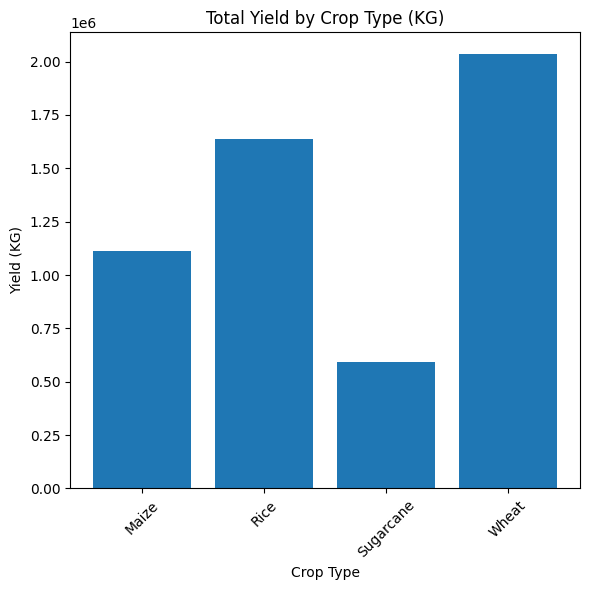

In [72]:
plt.figure(figsize=(6, 6))
plt.bar(crop_yield_by_type.index, crop_yield_by_type['YIELD_KG'])
plt.title('Total Yield by Crop Type (KG)')
plt.ylabel('Yield (KG)')
plt.xlabel('Crop Type')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

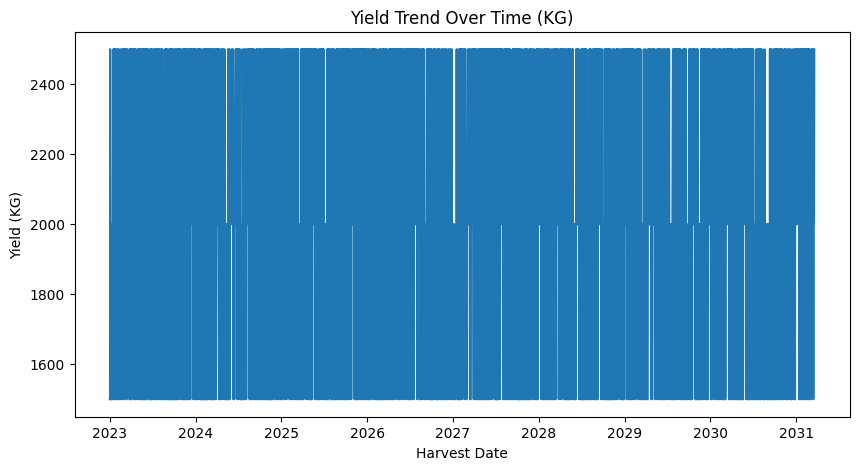

In [73]:
yield_pivot = crop_df.pivot_table(
    values='YIELD_KG', index='HARVEST_DATE', aggfunc='sum'
)

plt.figure(figsize=(10, 5))
plt.plot(yield_pivot.index, yield_pivot['YIELD_KG'])
plt.title('Yield Trend Over Time (KG)')
plt.ylabel('Yield (KG)')
plt.xlabel('Harvest Date')
plt.savefig('crop_yield_trend.png')
plt.show()